In [1]:
import os
import random
import zipfile
import copy
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import sympy
import sympy.printing
import torch
import torch.nn as nn
import torch.nn.functional as F
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from torch.utils.data import Dataset, DataLoader

ZIP_PATH = '/content/drive/MyDrive/shoplifting_CV/Shop DataSet.zip'
LOCAL_ROOT = '/content/data'
DATA_DIR = '/content/data/Shop DataSet'
CACHE_DIR = '/content/cache'
CLASS_TO_IDX = {'non shop lifters': 0, 'shop lifters': 1}
T = 16
RESIZE = (160, 196)
CROP = (144, 176)

if not os.path.isdir(DATA_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
    os.makedirs(LOCAL_ROOT, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL_ROOT)

os.makedirs(CACHE_DIR, exist_ok=True)
print('videos found:', sum(len([f for f in os.listdir(os.path.join(DATA_DIR, c)) if f.endswith('.mp4')]) for c in CLASS_TO_IDX))

videos found: 855


total clips: 855
class
non shop lifters    531
shop lifters        324
Name: count, dtype: int64

class           non shop lifters  shop lifters
frames   count        531.000000    324.000000
         mean         347.783427    304.601852
         std          134.202129     83.470572
         min           75.000000    100.000000
         25%          275.000000    248.000000
         50%          348.000000    300.000000
         75%          400.000000    372.000000
         max         1850.000000    570.000000
duration count        531.000000    324.000000
         mean          13.925970     12.223968
         std            5.367815      3.354683
         min            3.000000      4.000000
         25%           11.000000     10.000000
         50%           14.000000     12.000000
         75%           16.000000     15.000000
         max           74.000000     23.030303

width  height
704    576       855
dtype: int64

unreadable: 0
zero frames: 0
fps <= 0: 0


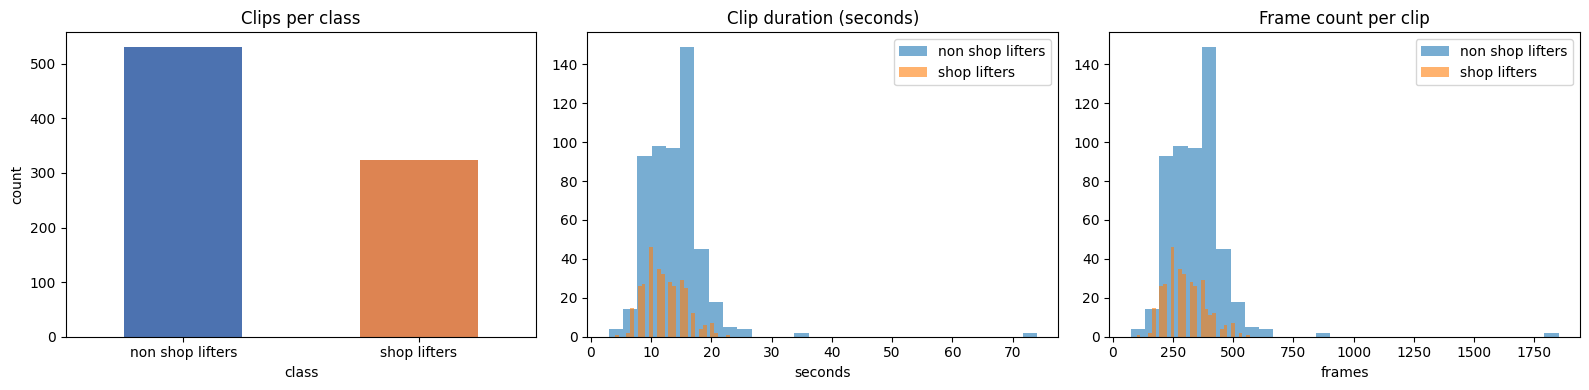

In [2]:
rows = []
for cls_name, label in CLASS_TO_IDX.items():
    cls_dir = os.path.join(DATA_DIR, cls_name)
    for fname in sorted(os.listdir(cls_dir)):
        if not fname.lower().endswith('.mp4'):
            continue
        path = os.path.join(cls_dir, fname)
        cap = cv2.VideoCapture(path)
        rows.append({
            'path': path,
            'class': cls_name,
            'label': label,
            'frames': int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
            'fps': cap.get(cv2.CAP_PROP_FPS),
            'width': int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
            'height': int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
            'opened': cap.isOpened(),
        })
        cap.release()

df = pd.DataFrame(rows)
df['duration'] = df['frames'] / df['fps'].where(df['fps'] > 0)
df['clip_id'] = df.index

print('total clips:', len(df))
print(df['class'].value_counts())
print()
print(df.groupby('class')[['frames', 'duration']].describe().T)
print()
print(df.groupby(['width', 'height']).size().sort_values(ascending=False))
print()
print('unreadable:', (~df['opened']).sum())
print('zero frames:', (df['frames'] <= 0).sum())
print('fps <= 0:', (df['fps'] <= 0).sum())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df['class'].value_counts().plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('Clips per class')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=0)
for cls_name in CLASS_TO_IDX:
    axes[1].hist(df.loc[df['class'] == cls_name, 'duration'].dropna(), bins=30, alpha=0.6, label=cls_name)
axes[1].set_title('Clip duration (seconds)')
axes[1].set_xlabel('seconds')
axes[1].legend()
for cls_name in CLASS_TO_IDX:
    axes[2].hist(df.loc[df['class'] == cls_name, 'frames'], bins=30, alpha=0.6, label=cls_name)
axes[2].set_title('Frame count per clip')
axes[2].set_xlabel('frames')
axes[2].legend()
plt.tight_layout()
plt.show()

frames=    5 | skip=   0.31 | first=   0 last=   4 | gap min=0 max=1
frames=   16 | skip=   1.00 | first=   0 last=  15 | gap min=1 max=1
frames=   75 | skip=   4.69 | first=   2 last=  72 | gap min=4 max=5
frames=  348 | skip=  21.75 | first=  10 last= 337 | gap min=21 max=22
frames=  570 | skip=  35.62 | first=  17 last= 552 | gap min=35 max=36
frames= 1850 | skip= 115.62 | first=  57 last=1792 | gap min=115 max=116


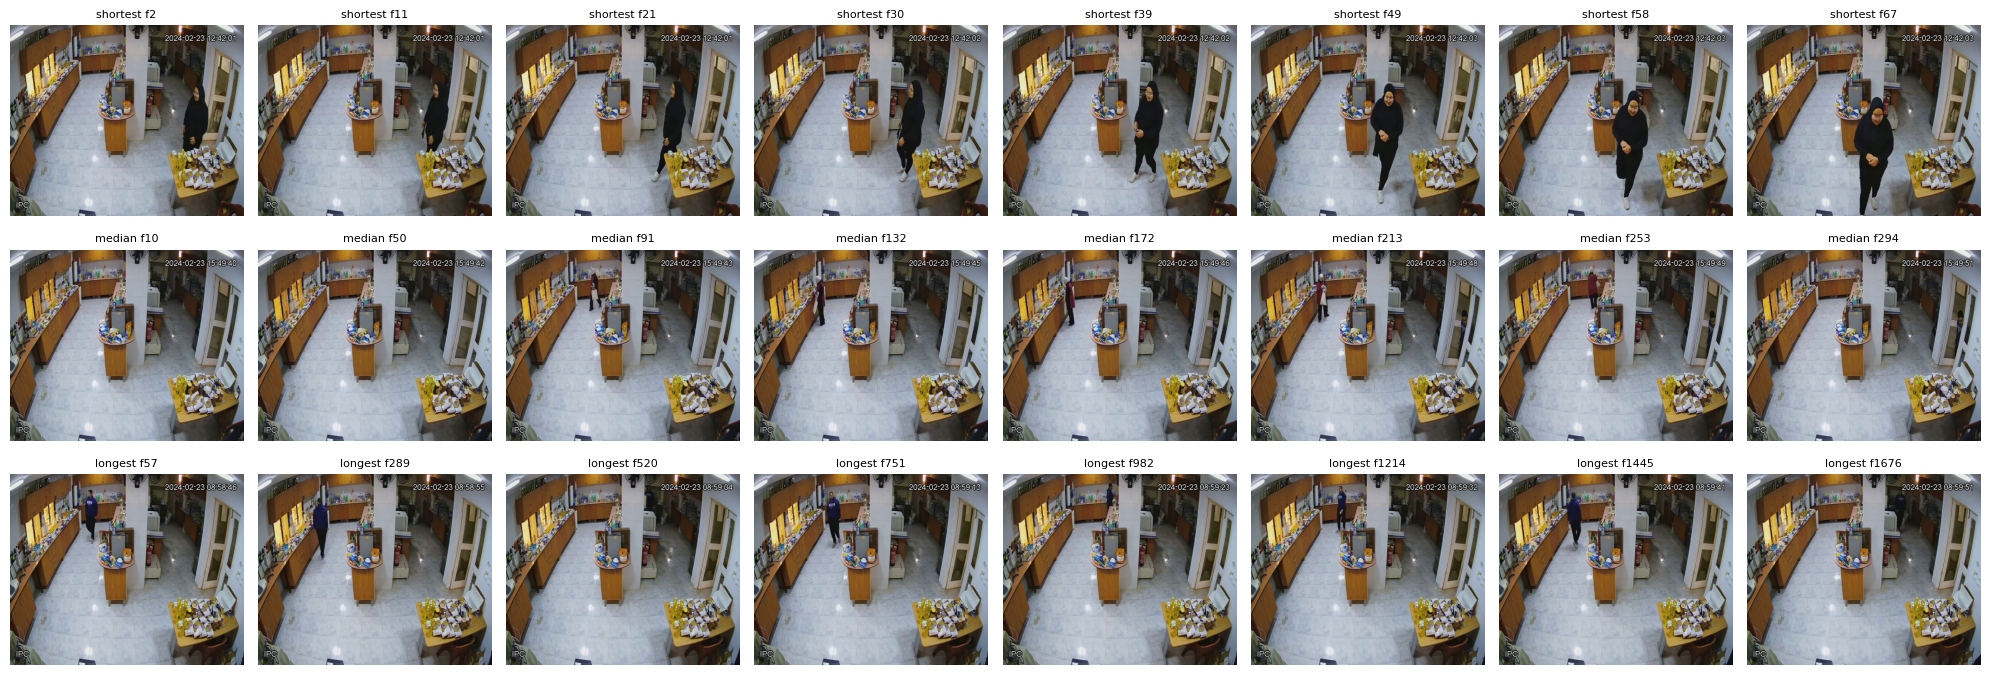

In [3]:
def get_frame_indices(total_frames, T):
    if total_frames <= 0:
        raise ValueError('total_frames must be positive')
    skip = total_frames / T
    idx = (np.arange(T) * skip + skip / 2).astype(int)
    return np.clip(idx, 0, total_frames - 1)

def read_frames(path, indices):
    cap = cv2.VideoCapture(path)
    frames = []
    last = None
    for i in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, frame = cap.read()
        if ok:
            last = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        if last is None:
            raise RuntimeError(f'could not read frame {i} from {path}')
        frames.append(last)
    cap.release()
    return np.stack(frames)

def read_frames_sequential(path, indices):
    wanted = {}
    for pos, i in enumerate(indices):
        wanted.setdefault(int(i), []).append(pos)
    out = [None] * len(indices)
    last_needed = max(wanted)
    cap = cv2.VideoCapture(path)
    i = 0
    while i <= last_needed:
        if not cap.grab():
            break
        if i in wanted:
            ok, frame = cap.retrieve()
            if ok:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                for p in wanted[i]:
                    out[p] = frame
        i += 1
    cap.release()
    last = None
    for p in range(len(out)):
        if out[p] is not None:
            last = out[p]
        elif last is not None:
            out[p] = last
    for p in range(len(out) - 1, -1, -1):
        if out[p] is None:
            out[p] = out[p + 1] if p + 1 < len(out) else None
    if any(f is None for f in out):
        raise RuntimeError(f'could not read frames from {path}')
    return np.stack(out)

for n in [5, 16, 75, 348, 570, 1850]:
    idx = get_frame_indices(n, T)
    gaps = np.diff(idx)
    print(f'frames={n:5d} | skip={n / T:7.2f} | first={idx[0]:4d} last={idx[-1]:4d} | gap min={gaps.min()} max={gaps.max()}')
    assert len(idx) == T
    assert idx.min() >= 0 and idx.max() <= n - 1

short = df.loc[df['frames'].idxmin()]
median = df.iloc[(df['frames'] - df['frames'].median()).abs().argsort().iloc[0]]
long_ = df.loc[df['frames'].idxmax()]

fig, axes = plt.subplots(3, 8, figsize=(20, 7))
for r, (name, row) in enumerate([('shortest', short), ('median', median), ('longest', long_)]):
    idx = get_frame_indices(int(row['frames']), T)
    frames = read_frames(row['path'], idx)
    assert frames.shape == (T, 576, 704, 3)
    for c in range(8):
        axes[r, c].imshow(frames[c * 2])
        axes[r, c].set_title(f'{name} f{idx[c * 2]}', fontsize=8)
        axes[r, c].axis('off')
plt.tight_layout()
plt.show()

check passed: 50 random augmentations, all T frames identical every time
negative control (independent per-frame aug) frames identical: False
aug seed 1 {'top': 4, 'left': 18, 'flip': False, 'brightness': 1.158, 'contrast': 0.853, 'saturation': 0.997}
aug seed 2 {'top': 1, 'left': 2, 'flip': True, 'brightness': 1.201, 'contrast': 1.142, 'saturation': 1.102}
aug seed 3 {'top': 7, 'left': 18, 'flip': False, 'brightness': 0.922, 'contrast': 1.062, 'saturation': 1.075}


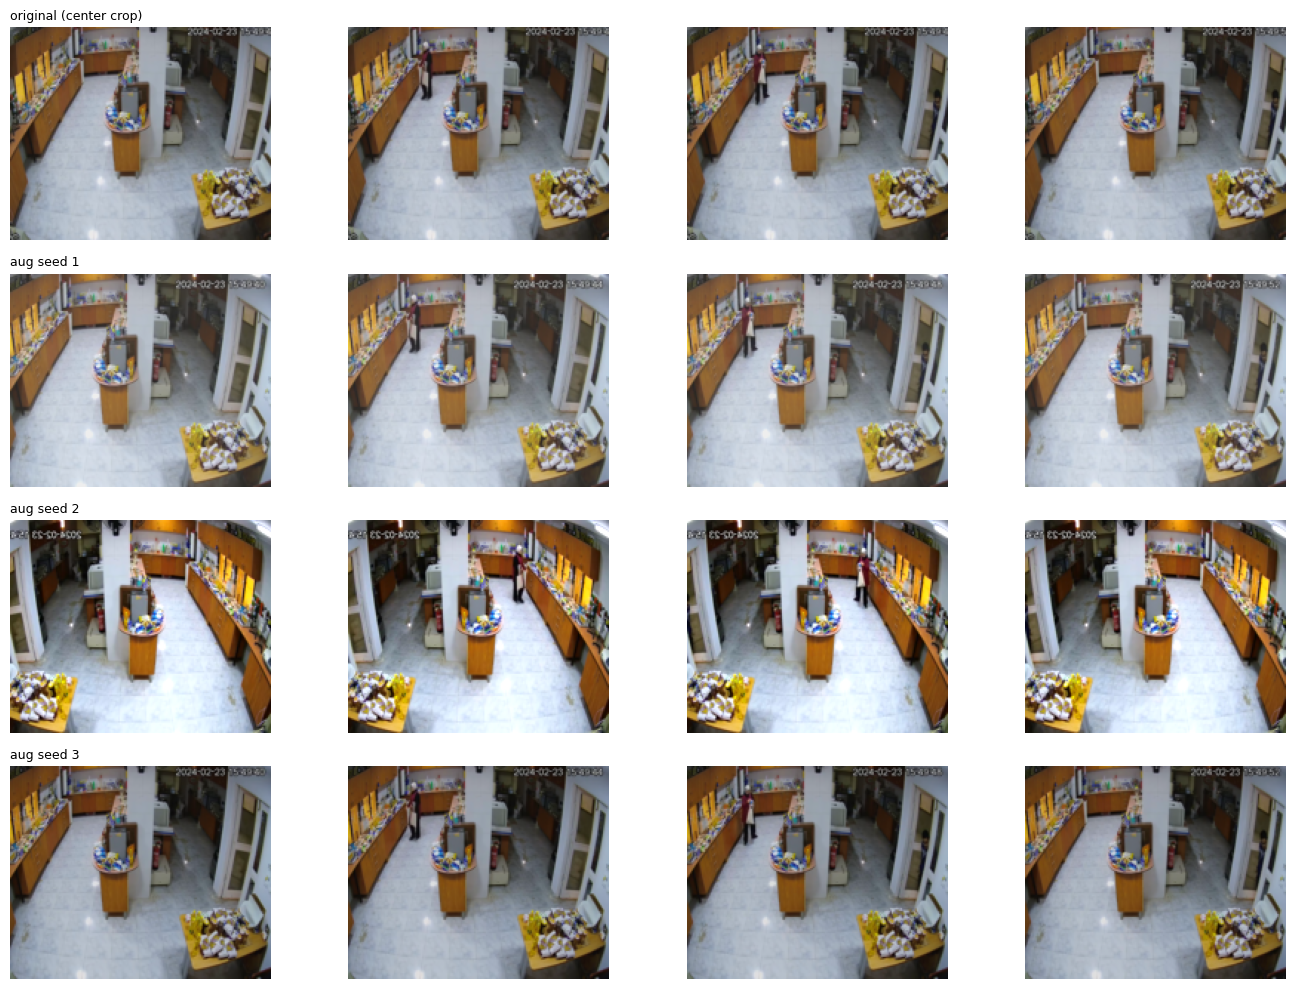

In [4]:
def augment_clip(clip, train=True):
    x = torch.from_numpy(clip).permute(0, 3, 1, 2).float() / 255.0
    x = F.interpolate(x, size=RESIZE, mode='bilinear', align_corners=False, antialias=True)
    rh, rw = RESIZE
    ch, cw = CROP
    if train:
        top = random.randint(0, rh - ch)
        left = random.randint(0, rw - cw)
        flip = random.random() < 0.5
        brightness = random.uniform(0.7, 1.3)
        contrast = random.uniform(0.7, 1.3)
        saturation = random.uniform(0.7, 1.3)
    else:
        top = (rh - ch) // 2
        left = (rw - cw) // 2
        flip = False
        brightness = contrast = saturation = 1.0
    x = x[:, :, top:top + ch, left:left + cw]
    if flip:
        x = torch.flip(x, dims=[3])
    x = (x * brightness).clamp(0, 1)
    mean = x.mean()
    x = ((x - mean) * contrast + mean).clamp(0, 1)
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
    x = ((x - gray) * saturation + gray).clamp(0, 1)
    params = dict(top=top, left=left, flip=flip, brightness=round(brightness, 3),
                  contrast=round(contrast, 3), saturation=round(saturation, 3))
    return x, params

idx = get_frame_indices(int(median['frames']), T)
frames = read_frames(median['path'], idx)

same_clip = np.stack([frames[0]] * T)
for seed in range(50):
    random.seed(seed)
    out, p = augment_clip(same_clip, train=True)
    assert out.shape == (T, 3, CROP[0], CROP[1])
    assert torch.equal(out, out[0:1].expand_as(out))
print('check passed: 50 random augmentations, all T frames identical every time')

random.seed(0)
independent = torch.stack([augment_clip(frames[i:i + 1], train=True)[0][0] for i in range(T)])
print('negative control (independent per-frame aug) frames identical:',
      torch.equal(independent[0:1].expand_as(independent), independent))

show = [0, 5, 10, 15]
demo_rows = [('original (center crop)', augment_clip(frames, train=False)[0], None)]
for seed in [1, 2, 3]:
    random.seed(seed)
    out, p = augment_clip(frames, train=True)
    demo_rows.append((f'aug seed {seed}', out, p))

fig, axes = plt.subplots(len(demo_rows), len(show), figsize=(14, 10))
for r, (name, clip_t, p) in enumerate(demo_rows):
    for c, f in enumerate(show):
        axes[r, c].imshow(clip_t[f].permute(1, 2, 0).numpy())
        axes[r, c].axis('off')
        if c == 0:
            axes[r, c].set_title(name, fontsize=9, loc='left')
    if p:
        print(name, p)
plt.tight_layout()
plt.show()

In [5]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

summary = pd.DataFrame({
    'train': train_df['label'].value_counts(),
    'val': val_df['label'].value_counts(),
    'test': test_df['label'].value_counts(),
}).rename(index={0: 'non shop lifters', 1: 'shop lifters'})
summary.loc['total'] = summary.sum()
print(summary)

assert not set(train_df['path']) & set(val_df['path'])
assert not set(train_df['path']) & set(test_df['path'])
assert not set(val_df['path']) & set(test_df['path'])
print('no overlap between splits')

                  train  val  test
label                             
non shop lifters    371   80    80
shop lifters        227   48    49
total               598  128   129
no overlap between splits


In [6]:
def cache_path_for(clip_id):
    return os.path.join(CACHE_DIR, f'{clip_id}.npy')

def build_cache_entry(row):
    out_path = cache_path_for(row.clip_id)
    if os.path.exists(out_path):
        return
    idx = get_frame_indices(int(row.frames), T)
    frames = read_frames_sequential(row.path, idx)
    small = np.stack([cv2.resize(f, (RESIZE[1], RESIZE[0]), interpolation=cv2.INTER_AREA) for f in frames])
    np.save(out_path, small)

rows_all = list(df.itertuples())
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    list(tqdm(ex.map(build_cache_entry, rows_all), total=len(rows_all)))

print('cached clips:', len(os.listdir(CACHE_DIR)))
sample = np.load(cache_path_for(df['clip_id'].iloc[0]))
print('cached clip shape:', sample.shape, sample.dtype)

  0%|          | 0/855 [00:00<?, ?it/s]

cached clips: 855
cached clip shape: (16, 160, 196, 3) uint8


In [7]:
class ShopliftingDataset(Dataset):
    def __init__(self, frame_df, T, train):
        self.df = frame_df.reset_index(drop=True)
        self.T = T
        self.train = train

    def __len__(self):
        return len(self.df)

    def load_frames(self, row):
        cp = cache_path_for(row['clip_id'])
        if os.path.exists(cp):
            return np.load(cp)
        idx = get_frame_indices(int(row['frames']), self.T)
        return read_frames_sequential(row['path'], idx)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        clip = self.load_frames(row)
        x, _ = augment_clip(clip, train=self.train)
        y = torch.tensor(int(row['label']), dtype=torch.long)
        return x, y

train_ds = ShopliftingDataset(train_df, T, train=True)
val_ds = ShopliftingDataset(val_df, T, train=False)
test_ds = ShopliftingDataset(test_df, T, train=False)

expected = (T, 3, CROP[0], CROP[1])
for name, ds in [('train', train_ds), ('val', val_ds), ('test', test_ds)]:
    for i in range(len(ds)):
        x, y = ds[i]
        assert tuple(x.shape) == expected, (name, i, x.shape)
        assert x.dtype == torch.float32
        assert 0.0 <= x.min() and x.max() <= 1.0
    print(f'{name}: {len(ds)} clips, all shape {expected}')

fallback_row = train_df.iloc[0].copy()
fallback_row['clip_id'] = -1
fb = train_ds.load_frames(fallback_row)
fb_x, _ = augment_clip(fb, train=False)
print('fallback path (no cache) output shape:', tuple(fb_x.shape))

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)
xb, yb = next(iter(train_loader))
print('batch:', tuple(xb.shape), tuple(yb.shape), yb.tolist())

train: 598 clips, all shape (16, 3, 144, 176)
val: 128 clips, all shape (16, 3, 144, 176)
test: 129 clips, all shape (16, 3, 144, 176)
fallback path (no cache) output shape: (16, 3, 144, 176)
batch: (8, 16, 3, 144, 176) (8,) [0, 0, 0, 0, 1, 1, 1, 0]


In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.relu = nn.ReLU(inplace=True)
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Sequential(
                nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                nn.BatchNorm2d(c_out),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + self.shortcut(x))

class ResFrameEncoder(nn.Module):
    def __init__(self, widths=(32, 64, 128, 256)):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(inplace=True),
        )
        self.stages = nn.Sequential(
            ResBlock(widths[0], widths[0], 1),
            ResBlock(widths[0], widths[1], 2),
            ResBlock(widths[1], widths[2], 2),
            ResBlock(widths[2], widths[3], 2),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = widths[3]

    def forward(self, x):
        return self.pool(self.stages(self.stem(x))).flatten(1)

class ResCNNLSTM(nn.Module):
    def __init__(self, hidden=128, num_classes=2):
        super().__init__()
        self.encoder = ResFrameEncoder()
        self.feat_drop = nn.Dropout(0.3)
        self.lstm = nn.LSTM(self.encoder.out_dim, hidden, num_layers=1,
                            batch_first=True, bidirectional=True)
        self.cls_drop = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden * 4, num_classes)
        for m in self.encoder.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        b, t, c, h, w = x.shape
        f = self.encoder(x.reshape(b * t, c, h, w)).reshape(b, t, -1)
        f = self.feat_drop(f)
        seq, _ = self.lstm(f)
        pooled = torch.cat([seq.mean(dim=1), seq.max(dim=1).values], dim=1)
        return self.fc(self.cls_drop(pooled))

model = ResCNNLSTM().to(device)
print(f'parameters: {sum(p.numel() for p in model.parameters()):,}')
with torch.no_grad():
    out = model(xb.to(device))
print('input:', tuple(xb.shape), '-> output:', tuple(out.shape))

device: cuda
parameters: 1,622,690
input: (8, 16, 3, 144, 176) -> output: (8, 2)


class weights: [0.806, 1.317]


epoch 1/70:   0%|          | 0/74 [00:00<?, ?it/s]

epoch  1 | train loss 0.7230 | val loss 0.6917 | val acc 0.6250 | prec 0.000 | rec 0.000 | f1 0.0000 | 28s *


epoch 2/70:   0%|          | 0/74 [00:00<?, ?it/s]

epoch  2 | train loss 0.7015 | val loss 0.7221 | val acc 0.6250 | prec 0.000 | rec 0.000 | f1 0.0000 | 17s


...

epoch 69/70:   0%|          | 0/74 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e1688d6c680>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e1688d6c680>

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()
assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
AssertionError    : if w.is_alive():can only test a child process

  File "/usr/lib/

epoch 69 | train loss 0.4064 | val loss 0.2124 | val acc 0.9297 | prec 0.953 | rec 0.854 | f1 0.9011 | 19s


epoch 70/70:   0%|          | 0/74 [00:00<?, ?it/s]

epoch 70 | train loss 0.3840 | val loss 0.2206 | val acc 0.9375 | prec 0.976 | rec 0.854 | f1 0.9111 | 18s
best val f1 0.9362 at epoch 55


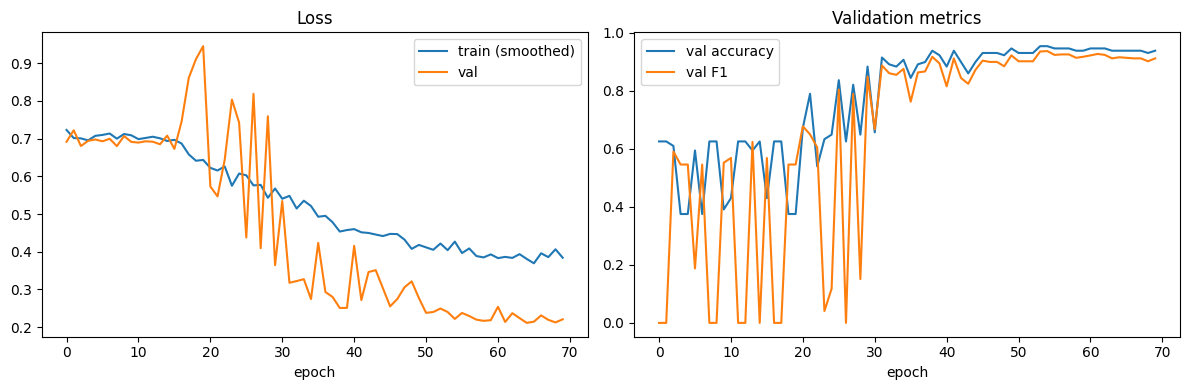

In [9]:
CONFIG = dict(
    epochs=70,
    patience=20,
    batch_size=8,
    lr=1e-3,
    weight_decay=5e-2,
    label_smoothing=0.1,
    grad_clip=1.0,
)

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

counts = train_df['label'].value_counts().sort_index().values
class_weights = torch.tensor(counts.sum() / (2.0 * counts), dtype=torch.float32).to(device)
print('class weights:', [round(w, 3) for w in class_weights.tolist()])

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'], shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=2)

model = ResCNNLSTM().to(device)

train_criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=CONFIG['label_smoothing'])
eval_criterion = nn.CrossEntropyLoss(weight=class_weights)

decay, no_decay = [], []
for p in model.parameters():
    (decay if p.ndim > 1 else no_decay).append(p)
optimizer = torch.optim.AdamW(
    [{'params': decay, 'weight_decay': CONFIG['weight_decay']},
     {'params': no_decay, 'weight_decay': 0.0}],
    lr=CONFIG['lr'],
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])
use_amp = device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_eval(loader):
    model.eval()
    losses, preds, labels = [], [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(x)
            loss = eval_criterion(logits.float(), y)
            losses.append(loss.item() * len(y))
            preds.extend(logits.argmax(1).cpu().tolist())
            labels.extend(y.cpu().tolist())
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average='binary', pos_label=1, zero_division=0)
    return {
        'loss': sum(losses) / len(labels),
        'acc': accuracy_score(labels, preds),
        'precision': p, 'recall': r, 'f1': f1,
        'preds': preds, 'labels': labels,
    }

history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_f1, best_loss, best_state, best_epoch, bad_epochs = -1.0, float('inf'), None, 0, 0

for epoch in range(1, CONFIG['epochs'] + 1):
    model.train()
    t0 = time.time()
    running, seen = 0.0, 0
    pbar = tqdm(train_loader, desc=f'epoch {epoch}/{CONFIG["epochs"]}', leave=False)
    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x)
        loss = train_criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['grad_clip'])
        scaler.step(optimizer)
        scaler.update()
        running += loss.item() * len(y)
        seen += len(y)
        pbar.set_postfix(loss=f'{running / seen:.4f}')
    scheduler.step()

    val = run_eval(val_loader)
    history['train_loss'].append(running / seen)
    history['val_loss'].append(val['loss'])
    history['val_acc'].append(val['acc'])
    history['val_f1'].append(val['f1'])

    improved = val['f1'] > best_f1 or (val['f1'] == best_f1 and val['loss'] < best_loss)
    if improved:
        best_f1, best_loss, best_epoch, bad_epochs = val['f1'], val['loss'], epoch, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        bad_epochs += 1

    print(f"epoch {epoch:2d} | train loss {running / seen:.4f} | val loss {val['loss']:.4f} | "
          f"val acc {val['acc']:.4f} | prec {val['precision']:.3f} | rec {val['recall']:.3f} | "
          f"f1 {val['f1']:.4f} | {time.time() - t0:.0f}s{' *' if improved else ''}")

    if bad_epochs >= CONFIG['patience']:
        print(f'early stopping at epoch {epoch}')
        break

print(f'best val f1 {best_f1:.4f} at epoch {best_epoch}')
torch.save(best_state, 'best_res_cnn_lstm.pt')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['train_loss'], label='train (smoothed)')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_title('Loss')
axes[0].set_xlabel('epoch')
axes[0].legend()
axes[1].plot(history['val_acc'], label='val accuracy')
axes[1].plot(history['val_f1'], label='val F1')
axes[1].set_title('Validation metrics')
axes[1].set_xlabel('epoch')
axes[1].legend()
plt.tight_layout()
plt.show()

test accuracy : 0.9457
test precision: 0.9773
test recall   : 0.8776
test F1       : 0.9247

              precision    recall  f1-score   support

      normal     0.9294    0.9875    0.9576        80
 shoplifting     0.9773    0.8776    0.9247        49

    accuracy                         0.9457       129
   macro avg     0.9533    0.9325    0.9412       129
weighted avg     0.9476    0.9457    0.9451       129



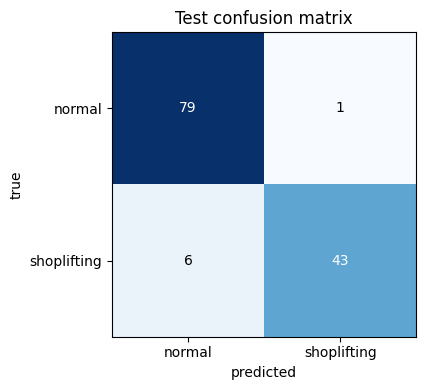

In [10]:
model.load_state_dict(torch.load('best_res_cnn_lstm.pt', map_location=device))
test = run_eval(test_loader)

print(f"test accuracy : {test['acc']:.4f}")
print(f"test precision: {test['precision']:.4f}")
print(f"test recall   : {test['recall']:.4f}")
print(f"test F1       : {test['f1']:.4f}")
print()
print(classification_report(test['labels'], test['preds'], target_names=['normal', 'shoplifting'], digits=4))

cm = confusion_matrix(test['labels'], test['preds'])
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['normal', 'shoplifting'])
ax.set_yticklabels(['normal', 'shoplifting'])
ax.set_xlabel('predicted')
ax.set_ylabel('true')
ax.set_title('Test confusion matrix')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

In [11]:
import json
import shutil
import subprocess
import sys

try:
    import onnx
    import onnxruntime as ort
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime'])
    import onnx
    import onnxruntime as ort

SAVE_DIR = '/content/shop_scratch'
DRIVE_DIR = '/content/drive/MyDrive/shop_scratch'
os.makedirs(SAVE_DIR, exist_ok=True)

model.load_state_dict(torch.load('best_res_cnn_lstm.pt', map_location=device))
model.eval()

torch.save(model.state_dict(), f'{SAVE_DIR}/shop_scratch.pt')

dummy = torch.randn(1, T, 3, CROP[0], CROP[1], device=device)
torch.onnx.export(
    model,
    dummy,
    f'{SAVE_DIR}/shop_scratch.onnx',
    input_names=['clip'],
    output_names=['logits'],
    dynamic_axes={'clip': {0: 'batch'}, 'logits': {0: 'batch'}},
    opset_version=17,
    dynamo=False,
)
onnx.checker.check_model(onnx.load(f'{SAVE_DIR}/shop_scratch.onnx'))

sess = ort.InferenceSession(f'{SAVE_DIR}/shop_scratch.onnx', providers=['CPUExecutionProvider'])
test_batch = torch.randn(4, T, 3, CROP[0], CROP[1])
with torch.no_grad():
    torch_out = model(test_batch.to(device)).float().cpu().numpy()
onnx_out = sess.run(None, {'clip': test_batch.numpy()})[0]
max_diff = float(np.abs(torch_out - onnx_out).max())
print('max abs difference torch vs onnx:', max_diff)
assert max_diff < 1e-3

meta = {
    'model': 'ResCNNLSTM (residual CNN encoder + BiLSTM), trained from scratch',
    'input_name': 'clip',
    'input_shape': ['batch', T, 3, CROP[0], CROP[1]],
    'input_dtype': 'float32',
    'input_range': '[0, 1], RGB, no mean/std normalization',
    'preprocessing': {
        'frames': T,
        'sampling': 'midpoint of T equal segments over the full video',
        'resize_hw': list(RESIZE),
        'center_crop_hw': list(CROP),
    },
    'output_name': 'logits',
    'classes': {'0': 'normal', '1': 'shoplifting'},
    'test_metrics': {
        'accuracy': round(float(test['acc']), 4),
        'precision': round(float(test['precision']), 4),
        'recall': round(float(test['recall']), 4),
        'f1': round(float(test['f1']), 4),
    },
}
with open(f'{SAVE_DIR}/shop_scratch_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

shutil.copytree(SAVE_DIR, DRIVE_DIR, dirs_exist_ok=True)
for name in sorted(os.listdir(DRIVE_DIR)):
    print(f'{name}: {os.path.getsize(os.path.join(DRIVE_DIR, name)) / 1e6:.2f} MB')
print('saved to', DRIVE_DIR)

/tmp/ipykernel_12433/4274858458.py:24: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py:4463: UserWarning: Exporting a model to ONNX with a batch_size other than 1, with a variable length with LSTM can cause an error when running the ONNX model with a different batch size. Make sure to save the model with a batch size of 1, or define the initial states (h0/c0) as inputs of the model. 
  return _generic_rnn(


max abs difference torch vs onnx: 2.86102294921875e-06
shop_scratch.onnx: 6.50 MB
shop_scratch.pt: 6.53 MB
shop_scratch_meta.json: 0.00 MB
saved to /content/drive/MyDrive/shop_scratch
